# 激活函數 (Activation Functions)

在上一篇，我們已經學會使用 `nn.Linear()` 建立全連接層，也知道神經元會根據 Weight、Bias 與輸入資料計算加權總和。

但這裡有個問題：如果神經網路只是一直進行加權相加，就算堆疊很多層，也無法真正學習複雜的非線性關係。這正是 Activation Function 要解決的問題。

## 線性與非線性 (Linear vs Nonlinear)

### 什麼是線性關係 (Linear Relationship)？

在機器學習中，常見的線性模型會使用以下形式：

$$ y=wx+b $$

其中：

| 符號      | 說明            |
| ------- | ------------- |
| $x$ | 輸入特徵 (Input)  |
| $w$ | 權重 (Weight)   |
| $b$ | 偏差 (Bias)     |
| $y$ | 輸出結果 (Output) |

例如，我們想根據讀書時數預測考試成績：

$$ \text{Score}=10\times\text{Hours}+30 $$

| 讀書時數 | 預測成績 |
| ---- | ---- |
| 1    | 40   |
| 2    | 50   |
| 3    | 60   |
| 4    | 70   |
| 5    | 80   |

每增加一小時，預測成績固定增加 10 分。這種關係可以用直線表示。

嚴格來說，`wx+b` 在數學上稱為仿射函數 (Affine Function)，但機器學習通常將它歸類為線性模型。

### 什麼是非線性關係 (Nonlinear Relationship)？

現實世界中的資料經常不是直線關係。

例如，讀書時間與考試成績可能出現以下情況：

- 剛開始讀書時，成績提升很快。
- 讀到一定程度後，成績提升逐漸變慢。
- 長時間疲勞學習，甚至可能使表現下降。

這時候，單一條直線就不容易描述完整關係。

其他常見的非線性例子包括顧客購買行為、房價與地理位置的關係，以及感測器訊號與設備故障的關係。

假設我們建立以下模型：

```py
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.Linear(16, 8),
    nn.Linear(8, 1)
)
```

這個模型看起來有三個全連接層，但因為中間沒有非線性激活函數，整個模型仍然可以合併成一次仿射轉換。

例如：

$$ h=2x+3 $$

再經過下一層：

$$ y=4h+5 $$

將第一層代入：

$$ y=4(2x+3)+5=8x+17 $$

結果仍然是一條直線。

因此，單純增加 `nn.Linear()` 的層數，不會讓模型具備真正的非線性表達能力。

加入激活函數後：

```py
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 1)
)
```

模型就能組合出更複雜的非線性函數。

### 實作：使用 Python 比較線性與非線性

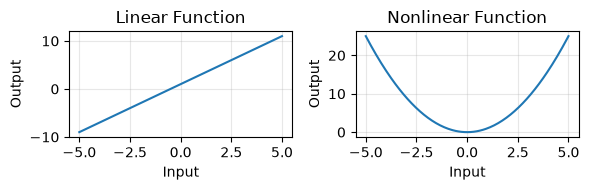

In [3]:
import numpy as np
import matplotlib.pyplot as plt


### 建立輸入資料
x = np.linspace(-5, 5, 200) # 在 -5 到 5 之間建立 200 個數值


### 建立線性函數
y_linear = 2 * x + 1 # 直線關係


### 建立非線性函數
y_nonlinear = x ** 2 # 拋物線關係


### 建立畫布
plt.figure(figsize=(6, 2))


### 繪製線性函數
plt.subplot(1, 2, 1)
plt.plot(x, y_linear)
plt.title("Linear Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(alpha=0.3)


### 繪製非線性函數
plt.subplot(1, 2, 2)
plt.plot(x, y_nonlinear)
plt.title("Nonlinear Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(alpha=0.3)


### 顯示圖表
plt.tight_layout()
plt.show()

## 激活函數 (Activation Function)

激活函數 (Activation Function) 是神經網路中的一種數學函數，負責將神經元計算出的數值轉換成新的輸出。

神經元的基本運作流程：

```
輸入 Features
      ↓
乘上 Weight
      ↓
加上 Bias
      ↓
加權總和 z
      ↓
Activation Function
      ↓
神經元輸出 a
```

![](./assets/激活函數.png)

## Sigmoid 激活函數

Sigmoid 是深度學習中常見的激活函數之一。它可以將任意實數轉換成介於 0 與 1 之間的數值。

$$ \boxed{\sigma(x)=\frac{1}{1+e^{-x}}} $$

> 這個公式不需要背誦，理解輸出特性即可。

Sigmoid 的圖形是一條 S 型曲線。

它有幾個特性：

- 輸出永遠介於 0 與 1 之間。
- 輸入為 0 時，輸出為 0.5。
- 輸入越大，輸出越接近 1。
- 輸入越小，輸出越接近 0。

### Sigmoid 的應用

Sigmoid 特別適合用於二元分類的機率輸出。

例如，模型要預測顧客是否購買商品：

```text
ANN
 ↓
Logit = 2.0
 ↓
Sigmoid
 ↓
Probability ≈ 0.8808
 ↓
預測購買 (1)
```

這裡的 0.8808 代表模型估計的正類別機率，並不保證實際事件有完全校準的 88.08% 發生機率。

### 實作：使用 PyTorch 實作 Sigmoid

In [4]:
import torch
import torch.nn as nn


### 建立輸入資料
X = torch.tensor([
    -5.0,
    -2.0,
    0.0,
    2.0,
    5.0
])


### 建立 Sigmoid 激活函數
sigmoid = nn.Sigmoid()


### 執行 Sigmoid
output = sigmoid(X)


### 顯示結果
print("輸入：", X)
print("輸出：", output)

輸入： tensor([-5., -2.,  0.,  2.,  5.])
輸出： tensor([0.0067, 0.1192, 0.5000, 0.8808, 0.9933])


### Sigmoid的限制：梯度消失

Sigmoid 在輸入非常大或非常小時，輸出會逐漸接近 1 或 0。這些區域的曲線非常平坦，代表導數接近 0。

當神經網路很深時，反向傳播需要連續傳遞梯度，如果多個神經元都處於這種飽和區域，就可能造成梯度消失 (Vanishing Gradient)。結果可能是模型參數更新得非常緩慢，訓練效率下降。

因此，現代 ANN 通常不會將 Sigmoid 當成所有隱藏層的預設選擇。

![](./assets/Sigmoid的限制.png)



## Tanh 激活函數

Tanh (Hyperbolic Tangent，雙曲正切函數) 與 Sigmoid 類似，也具有 S 型曲線。但 Tanh 的輸出範圍是 -1 到 1。

Tanh 曾廣泛應用於傳統神經網路的隱藏層，也常見於 RNN、LSTM 與 GRU 的內部計算。例如，在循環神經網路中，Tanh 可以用來產生介於 -1 與 1 的隱藏狀態或候選狀態。不過Tanh 也會在輸入絕對值很大時進入飽和區域，因此同樣可能面臨梯度消失問題。

$$ \boxed{\tanh(x)=\frac{e^x-e^{-x}}{e^x+e^{-x}}} $$

| 輸入 $x$ | Tanh 輸出 (約) |
| ---------- | ----------- |
| -5         | -0.9999     |
| -2         | -0.9640     |
| 0          | 0.0000      |
| 2          | 0.9640      |
| 5          | 0.9999      |

與 Sigmoid 最大的差異是，Tanh 的輸出以 0 為中心。

例如：

```
Sigmoid(-2) ≈ 0.119
Tanh(-2)    ≈ -0.964
```

Tanh 可以保留輸出值的正負方向，而 Sigmoid 的輸出永遠是正數。

![](./assets/Tanh.png)

### Tanh 與 Sigmoid 比較

| 比較項目        | Sigmoid     | Tanh           |
| ----------- | ----------- | -------------- |
| 輸出範圍        | 0～1         | -1～1           |
| 輸出是否以 0 為中心 | 否           | 是              |
| 輸入為 0 的輸出   | 0.5         | 0              |
| 是否可能梯度消失    | 是           | 是              |
| 常見用途        | 二元分類機率、門控機制 | RNN 隱藏狀態、部分隱藏層 |


### 實作：使用 PyTorch 實作 Tanh

In [5]:
import torch
import torch.nn as nn


### 建立輸入資料
X = torch.tensor([
    -5.0,
    -2.0,
    0.0,
    2.0,
    5.0
])


### 建立 Tanh 激活函數
tanh = nn.Tanh()


### 執行 Tanh
output = tanh(X)


### 顯示結果
print("輸入：", X)
print("輸出：", output)

輸入： tensor([-5., -2.,  0.,  2.,  5.])
輸出： tensor([-0.9999, -0.9640,  0.0000,  0.9640,  0.9999])


## ReLU 激活函數

ReLU (Rectified Linear Unit，修正線性單元) 是現代深度學習中非常常見的隱藏層激活函數。

它的計算方式相當簡單：

$$ \boxed{\operatorname{ReLU}(x)=\max(0,x)} $$

白話來說：

- 輸入小於 0，輸出 0。
- 輸入大於 0，輸出維持原值。
- 輸入等於 0，輸出 0。

![](./assets/ReLU.png)

### 實作：使用 PyTorch 實作 ReLU

In [6]:
import torch
import torch.nn as nn


### 建立輸入資料
X = torch.tensor([
    -5.0,
    -2.0,
    0.0,
    2.0,
    5.0
])


### 建立 ReLU
relu = nn.ReLU()


### 執行 ReLU
output = relu(X)


### 顯示結果
print("輸入：", X)
print("輸出：", output)

輸入： tensor([-5., -2.,  0.,  2.,  5.])
輸出： tensor([0., 0., 0., 2., 5.])


## Leaky ReLU 激活函數

### 6.1 什麼是 Leaky ReLU？

Leaky ReLU 是 ReLU 的改良版本。

它保留 ReLU 在正數區域的特性，但允許負數輸入保留一小部分輸出，而不是直接變成 0。

公式：

$$ \operatorname{LeakyReLU}(x)= \begin{cases} x,&x\geq0\\\ \alpha x,&x<0 \end{cases} $$

其中 $\alpha$ 是負數區域的斜率。

例如，設定：

$$ \alpha=0.01 $$

輸出結果：

| 輸入 | ReLU | Leaky ReLU |
| -- | ---- | ---------- |
| -5 | 0    | -0.05      |
| -2 | 0    | -0.02      |
| 0  | 0    | 0          |
| 2  | 2    | 2          |
| 5  | 5    | 5          |

可以看到，Leaky ReLU 在負數區域仍然保留一個小斜率。

### 6.2 Leaky ReLU 的優點

Leaky ReLU 的主要設計目的是減少 Dying ReLU 問題。因為負數區域的梯度不再完全等於 0，所以神經元在負數區域仍有機會更新參數。但它不保證一定比 ReLU 更準確，也無法完全解決所有訓練問題。

![](./assets/Leaky%20ReLU.png)

### 實作：使用 PyTorch 實作 Leaky ReLU

In [7]:
import torch
import torch.nn as nn


### 建立輸入資料
X = torch.tensor([
    -5.0,
    -2.0,
    0.0,
    2.0,
    5.0
])


### 建立 Leaky ReLU
leaky_relu = nn.LeakyReLU(
    negative_slope=0.01 # 負數區域的斜率
)


### 執行 Leaky ReLU
output = leaky_relu(X)


### 顯示結果
print("輸入：", X)
print("輸出：", output)

輸入： tensor([-5., -2.,  0.,  2.,  5.])
輸出： tensor([-0.0500, -0.0200,  0.0000,  2.0000,  5.0000])


## Softmax 激活函數

![](./assets/Softmax.png)

### 實作：使用 PyTorch 實作 Softmax

In [8]:
import torch
import torch.nn as nn


### 建立三個類別的 Logits
logits = torch.tensor([
    [2.0, 1.0, 0.1]
])


### 建立 Softmax
softmax = nn.Softmax(
    dim=1 # 沿著類別維度計算 Softmax
)


### 計算機率
probabilities = softmax(logits)


### 顯示結果
print("原始 Logits：")
print(logits)

print("\nSoftmax 機率：")
print(probabilities)

print("\n機率總和：")
print(probabilities.sum(dim=1))

原始 Logits：
tensor([[2.0000, 1.0000, 0.1000]])

Softmax 機率：
tensor([[0.6590, 0.2424, 0.0986]])

機率總和：
tensor([1.0000])


### Softmax 的 dim 參數

這是使用 Softmax 時非常重要的參數。

![](./assets/Softmax%20的%20dim%20參數.png)